# 05 · Preprocessing & encoding

**Goal recap:** predict next-6-month `y_buy` / `y_spend` per customer at a cutoff. Notebook 04 built 27 features and handed over a to-do list:
missing gap values, heavily skewed amounts, very different scales, and a 37-level country column.

**This notebook's question:** *how should raw features be transformed before a model sees them, and does it actually matter?*

### Why preprocessing depends on the model
| Step | Linear / NN models | Trees (LightGBM, HGB) |
|---|---|---|
| Missing values | must be filled (they can't do arithmetic on NaN) | handled natively (NaN gets its own branch) |
| Skew / outliers | a £500k customer drags the whole fit, so log or clip | splits only use *order*, so no effect |
| Scaling | needed: the penalty and the optimiser assume comparable scales | irrelevant: a split on £ or on z-score is the same split |
| Categories | must become numbers (one-hot / target encoding) | same, but more forgiving |

### The rule that makes it leak-proof
**Every preprocessing step that learns a number from data is part of the model.** A median, a mean and std, a clipping quantile, a category's average target:
each must be **fit on training rows only**, then applied unchanged to validation and test. A sklearn `Pipeline` guarantees that, because `fit` only ever sees training rows.

### How we'll decide (the experiment design)
Hold **one simple model fixed** (logistic regression for `y_buy`) and change **one preprocessing choice at a time**. Score each variant on the **4 time folds** from notebook 03
(validate Sep / Oct / Nov / Dec 2010, each trained on the cutoffs whose labels had matured). We look at **per-fold** differences, not just the average.
A choice that wins in every fold is convincing; one that wins on average because of one fold isn't.

### 🧠 Predict first
1. Will a **log transform** of the skewed spend/count features help logistic regression?
2. Notebook 04 showed missing gaps are informative (one-day buyers return less). Will a **missing-indicator** column help?
3. Which **country encoding** wins (one-hot, rare-grouping, target encoding), and by how much?
4. Will log-transforming the features change a **tree** model's predictions?

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET
from src.split import TRAIN_CUTOFFS, time_folds, monthly_cutoffs
from src.preprocess import (make_linear_preprocessor, make_tree_preprocessor, MODEL_INPUTS,
                            NUM_FEATURES, SKEWED, NOT_LEARNABLE_YET)

pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)

table = pd.read_parquet(Path(CLEAN_PARQUET).parent / "features.parquet")
FOLDS = time_folds(monthly_cutoffs("2010-09", "2010-12"))
FOLD_NAMES = [v.strftime("%b") for _, v in FOLDS]
print(f"{len(NUM_FEATURES)} numeric features used; held out for now (not learnable in selection, nb 04): {NOT_LEARNABLE_YET}")
for tc, v in FOLDS:
    print(f"  fold {v.strftime('%b %Y')}: train on {len(tc)} cutoffs ({tc[0].strftime('%b')}–{tc[-1].strftime('%b')})")

21 numeric features used; held out for now (not learnable in selection, nb 04): ['spend_trend', 'days_trend', 'history_days', 'peak_days_in_window']
  fold Sep 2010: train on 3 cutoffs (Jan–Mar)
  fold Oct 2010: train on 4 cutoffs (Jan–Apr)
  fold Nov 2010: train on 5 cutoffs (Jan–May)
  fold Dec 2010: train on 6 cutoffs (Jan–Jun)


In [2]:
def fold_auc(make_model, target: str = "y_buy") -> dict:
    # Fit a fresh pipeline per fold on that fold's training cutoffs; return validation AUC per fold.
    out, n_warn, train_auc = {}, 0, []
    for (train_cuts, v), name in zip(FOLDS, FOLD_NAMES):
        tr, va = table[table["cutoff"].isin(train_cuts)], table[table["cutoff"] == v]
        model = make_model()
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(tr[MODEL_INPUTS], tr[target])
        n_warn += sum(issubclass(x.category, ConvergenceWarning) for x in w)
        out[name] = roc_auc_score(va[target], model.predict_proba(va[MODEL_INPUTS])[:, 1])
        train_auc.append(roc_auc_score(tr[target], model.predict_proba(tr[MODEL_INPUTS])[:, 1]))
    return {**out, "mean": np.mean(list(out.values())), "train_auc": np.mean(train_auc), "conv_warnings": n_warn}


def logreg(**prep):
    return lambda: Pipeline([("prep", make_linear_preprocessor(**prep)), ("model", LogisticRegression(max_iter=2000))])


def compare(variants: dict) -> pd.DataFrame:
    return pd.DataFrame({name: fold_auc(make) for name, make in variants.items()}).T


def plot_folds(res: pd.DataFrame, title: str, ref: str = None):
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(res) + 1.2))
    for i, (fold, m) in enumerate(zip(FOLD_NAMES, "osD^")):
        ax.scatter(res[fold], range(len(res)), marker=m, s=45, label=f"{fold} fold", zorder=3)
    ax.scatter(res["mean"], range(len(res)), marker="|", s=400, color="black", label="mean", zorder=4)
    if ref is not None:
        ax.axvline(res.loc[ref, "mean"], color="grey", ls=":", lw=1)
    ax.set_yticks(range(len(res)), res.index)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Validation ROC-AUC (y_buy)")
    ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.25 if len(res) < 4 else -0.12))
    plt.tight_layout()
    plt.show()


baseline = {name: roc_auc_score(table.loc[table["cutoff"] == v, "y_buy"], table.loc[table["cutoff"] == v, "spend_180d"])
            for (_, v), name in zip(FOLDS, FOLD_NAMES)}
print("Bar to beat (naive 'spend in last 180 days' score):", {k: round(x, 3) for k, x in baseline.items()},
      f"mean {np.mean(list(baseline.values())):.3f}")

Bar to beat (naive 'spend in last 180 days' score): {'Sep': np.float64(0.706), 'Oct': np.float64(0.71), 'Nov': np.float64(0.724), 'Dec': np.float64(0.752)} mean 0.723


## 1. Missing values: median fill vs. median fill + missing-indicator
Gap features (`gap_mean`, `gap_last`, `overdue_ratio`, `gap_std`) are missing for one-day buyers. Options:
- **Median imputation:** fill with the training median. Simple, but it pretends a one-day buyer has an average rhythm.
- **Median + missing-indicator:** also add a 0/1 column "was missing", so the model can learn that one-day buyers differ. Textbook choice when missingness is informative.

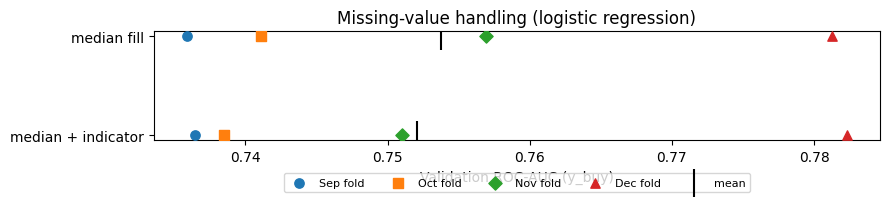

,Sep,Oct,Nov,Dec,mean,train_auc,conv_warnings
median fill,0.7359,0.7411,0.757,0.7812,0.7538,0.7233,0.0
median + indicator,0.7364,0.7385,0.751,0.7823,0.7521,0.7237,0.0


In [3]:
res_missing = compare({"median fill": logreg(missing="median"), "median + indicator": logreg(missing="indicator")})
plot_folds(res_missing, "Missing-value handling (logistic regression)")
res_missing.round(4)

**Takeaway:** the indicator **adds nothing**: it wins 2 folds and loses 2, all within about 0.006 AUC, which is noise-level. (While preparing this notebook, with log-transformed features, it was worse in 3 of 4 folds.)
Why no gain, when notebook 04 showed missingness is informative? Look at what "one-day buyer" *means* at each cutoff:

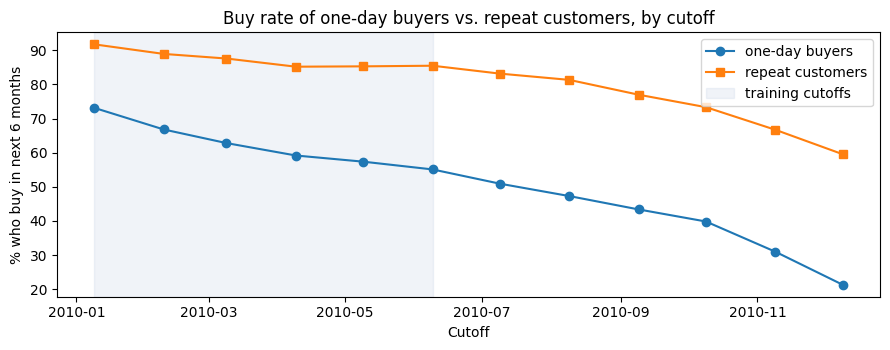

In [4]:
t = table.assign(one_day=table["gap_mean"].isna())
drift = t.groupby(["cutoff", "one_day"])["y_buy"].mean().unstack().rename(columns={True: "one-day buyers", False: "repeat customers"})

fig, ax = plt.subplots(figsize=(9, 3.6))
for col, m in [("one-day buyers", "o"), ("repeat customers", "s")]:
    ax.plot(drift.index, drift[col] * 100, marker=m, label=col)
ax.axvspan(TRAIN_CUTOFFS[0], TRAIN_CUTOFFS[-1], color="#4C72B0", alpha=0.08, label="training cutoffs")
ax.set_title("Buy rate of one-day buyers vs. repeat customers, by cutoff")
ax.set_xlabel("Cutoff")
ax.set_ylabel("% who buy in next 6 months")
ax.legend()
plt.tight_layout()
plt.show()

**Takeaway:** at the January cutoff a one-day buyer is mostly a **brand-new customer** (73% buy again). By December it's mostly a **long-dormant one-timer** (21% buy again).
The gap to repeat customers grows from about 20 to about 40 points. So whatever the indicator learns on early cutoffs describes a group that has changed by validation time, and its in-sample advantage doesn't carry over.

**Lesson:** *"informative missingness"* measured within a period doesn't guarantee a stable signal **across time**. When the population behind the missing values changes, the indicator encodes yesterday's population.
This is the third appearance of the same theme (history length changes what features mean). **Decision:** median imputation for linear models; trees will use native NaN handling, re-checked in notebook 08.

## 2. Skew & outliers: nothing vs. clip vs. log
Spend and count features have skewness up to about 20 (notebook 04). Options for a linear model:
- **None:** use raw values (after scaling). Giant customers sit far out.
- **Clip (winsorize):** cap each feature at its training 1st/99th percentile.
- **log1p:** compress multiplicative differences (£100 → £10k becomes 2 → 4).

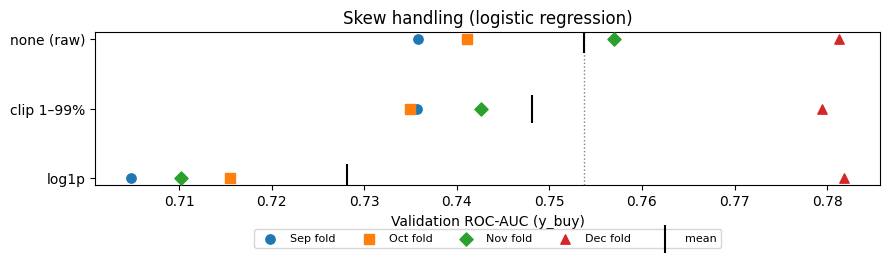

,Sep,Oct,Nov,Dec,mean,train_auc,conv_warnings
none (raw),0.7359,0.7411,0.7570,0.7812,0.7538,0.7233,0.0
clip 1–99%,0.7357,0.7349,0.7426,0.7794,0.7482,0.7322,0.0
log1p,0.7048,0.7155,0.7102,0.7819,0.7281,0.7316,0.0


In [5]:
res_skew = compare({"none (raw)": logreg(skew="none"), "clip 1–99%": logreg(skew="clip"), "log1p": logreg(skew="log")})
plot_folds(res_skew, "Skew handling (logistic regression)", ref="none (raw)")
res_skew.round(4)

**Takeaway:** the textbook favourite, **log1p, is the worst here**, and raw is best on average. But look *where* the differences are:
- In the **Sep–Nov folds** (trained on only 3–5 early cutoffs with short histories), the variants differ by up to about 0.05 AUC.
- In the **December fold** (6 training cutoffs, the real validation setup), all three are within about 0.003, which is noise-level (notebook 03's CI half-width ≈ 0.015).

So skew handling isn't what's driving these numbers. **What the early folds measure is how well each version of the features survives the shift from short-history training rows to long-history validation rows.**
Logging the *count* features gives extra resolution at the low end (0 vs. 1 vs. 2 purchase days), exactly where "new customer" vs. "dormant customer" changes meaning across cutoffs.
(A quick check while preparing this notebook: logging the spend features but *not* the counts recovers about half of the gap.)

**A caution about our own process:** we've now compared about 10 variants on the same 4 folds. Picking whichever has the highest mean is **overfitting to the validation folds**
(the "garden of forking paths"). So the decision rule is: *adopt a change only if it wins or ties in every fold.*
- **Decision:** **no skew transform** for logistic regression (wins or ties in all 4 folds). Clipping is an acceptable alternative.
- **This is not "log is bad".** For the **target** (`y_spend`, notebook 07), log1p has a different job (stop the loss from being dominated by a few customers) and is tested separately.

## 3. Scaling: does it matter for logistic regression?

In [6]:
res_scale = compare({"scaled": logreg(scale=True), "not scaled": logreg(scale=False)})
res_scale.round(4)

,Sep,Oct,Nov,Dec,mean,train_auc,conv_warnings
scaled,0.7359,0.7411,0.7570,0.7812,0.7538,0.7233,0.0
not scaled,0.7237,0.7299,0.7408,0.7801,0.7436,0.7220,4.0


In [7]:
def coef_table(scale: bool) -> pd.Series:
    tr = table[table["cutoff"].isin(TRAIN_CUTOFFS)]
    m = logreg(scale=scale)()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m.fit(tr[MODEL_INPUTS], tr["y_buy"])
    return pd.Series(m[-1].coef_[0], index=m[0].get_feature_names_out())


coefs = pd.DataFrame({"scaled": coef_table(True), "not scaled": coef_table(False)})
coefs.loc[["spend_180d", "n_days_180d", "recency_days", "tenure_days", "avg_items_per_day"]].round(4)

,scaled,not scaled
spend_180d,-0.2374,-0.0001
n_days_180d,-0.0117,0.1021
recency_days,-0.4825,-0.0102
tenure_days,0.6098,0.0093
avg_items_per_day,-0.0927,-0.0001


**Takeaway:** scaling wins in all 4 folds (by 0.001–0.016 AUC), and without it the optimiser **fails to converge** in every fold (`conv_warnings` = 4).
Unscaled coefficients are incomparable: `spend_180d` gets a near-zero coefficient because it's measured in £ (often thousands), while day-counted features get bigger numbers.

**And a warning from the scaled column:** `spend_180d`, the strongest single feature in notebook 04, gets a **negative** coefficient. That's not a bug. Its information is shared with
`spend_90d`, `spend_per_month` and the other correlated spend features, so the model splits and offsets credit among them (multicollinearity). **Never read individual coefficients of correlated features as "effects".**
Scaling matters less for accuracy than for **two other things**:
1. **Regularisation is fair:** the L2 penalty shrinks all coefficients equally, which only makes sense if features are on one scale. Unscaled, it effectively penalises small-unit features more.
2. **Coefficients are comparable:** "1 standard deviation more recency" vs. "1 SD more spend".

**Decision:** standardise for linear models and the MLP (notebook 09). **Trees:** next section.

## 4. Trees don't care about monotone transforms
A tree split asks *"is spend_180d > £740?"*. Applying log first just asks *"is log(spend_180d) > 6.6?"*: the same split, the same customers on each side.

In [8]:
log_skewed = ColumnTransformer([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), SKEWED),
                                ("rest", "passthrough", [c for c in NUM_FEATURES if c not in SKEWED] + ["is_uk"])],
                               verbose_feature_names_out=False)


def hgb(prep):
    return lambda: Pipeline([("prep", prep()), ("model", HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, random_state=SEED))])


res_tree = compare({"HGB raw (NaN kept)": hgb(make_tree_preprocessor), "HGB log1p (NaN kept)": hgb(lambda: log_skewed)})
res_tree.round(4)

,Sep,Oct,Nov,Dec,mean,train_auc,conv_warnings
HGB raw (NaN kept),0.7029,0.7109,0.7287,0.7523,0.7237,0.9610,0.0
HGB log1p (NaN kept),0.7047,0.7091,0.7309,0.7523,0.7242,0.9618,0.0


**Takeaway:** raw and log1p give the **same** tree model (identical or near-identical AUC; tiny differences can come from histogram binning).
So for LightGBM in notebook 06: **no log, no scaling, NaN left as NaN.** That's one of the practical reasons GBMs are the default for tabular data.

**Warning sign worth noticing now:** the untuned tree has **training AUC ≈ 0.96 vs. validation ≈ 0.72**. That's heavy overfitting, and it's worse than logistic regression in the December fold.
With about 2.8k distinct customers behind about 11k correlated rows, a default-sized GBM memorises. That's the tuning agenda for notebook 08 (fewer leaves, larger `min_child_samples`, stronger regularisation, early stopping).

## 5. Country encoding
92% of customers are UK; the other 36 countries are small, and several have a **single customer** in the training data:

In [9]:
tr_all = table[table["cutoff"].isin(TRAIN_CUTOFFS)]
per_country = tr_all.groupby("country").agg(customers=("Customer ID", "nunique"), rows=("y_buy", "size"), buy_rate=("y_buy", "mean"))
print(f"{(per_country['customers'] == 1).sum()} countries have exactly 1 customer in training; "
      f"{(per_country['rows'] < 30).sum()} have < 30 training rows")
per_country.sort_values("customers").head(8).round(2)

6 countries have exactly 1 customer in training; 20 have < 30 training rows


,customers,rows,buy_rate
country,,,
Bahrain,1,1,0.00
Singapore,1,2,1.00
RSA,1,5,0.00
Poland,1,6,1.00
Norway,1,6,0.00
Malta,1,5,0.80
Japan,2,10,1.00
United Arab Emirates,3,13,0.31


| Encoding | How | Risk |
|---|---|---|
| **none** | ignore country | lose real market differences |
| **is_uk** | one 0/1 column | lumps 36 countries together |
| **one-hot** | one column per country | many near-empty columns: overfits rare countries |
| **one-hot + rare grouping** | countries with < 30 training rows share an "other" column | loses detail for mid-size countries |
| **target encoding (out-of-fold by customer)** | replace country by its smoothed training buy rate, computed without the row's own customer | the smart option for high-cardinality categories |
| **target encoding (naive)** | same, but computed on all training rows including the row itself, no smoothing | **leaks**: a one-customer country's encoding *is* that customer's outcome |

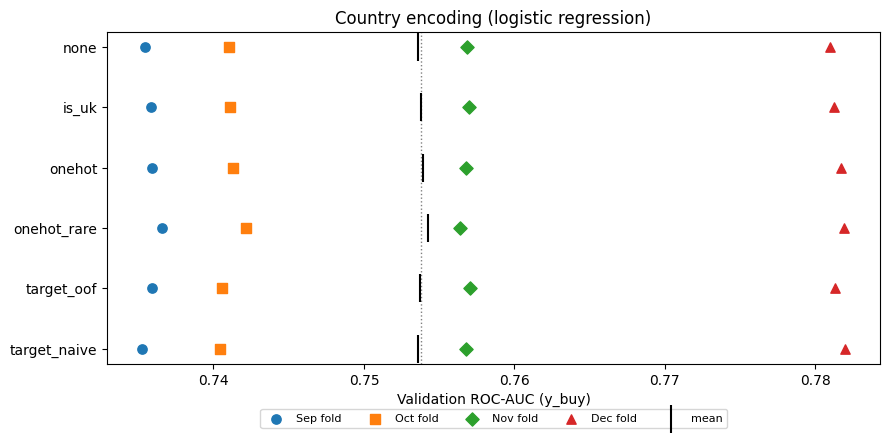

,Sep,Oct,Nov,Dec,mean,train_auc,conv_warnings,train − val gap
none,0.7355,0.7410,0.7568,0.7810,0.7536,0.7228,0.0,-0.0308
is_uk,0.7359,0.7411,0.7570,0.7812,0.7538,0.7233,0.0,-0.0305
onehot,0.7359,0.7413,0.7568,0.7817,0.7539,0.7310,0.0,-0.0229
onehot_rare,0.7366,0.7422,0.7564,0.7819,0.7543,0.7238,0.0,-0.0304
target_oof,0.7359,0.7406,0.7571,0.7813,0.7537,0.7229,0.0,-0.0308
target_naive,0.7353,0.7404,0.7568,0.7820,0.7536,0.7304,0.0,-0.0232


In [10]:
res_country = compare({c: logreg(country=c) for c in ["none", "is_uk", "onehot", "onehot_rare", "target_oof", "target_naive"]})
res_country["train − val gap"] = res_country["train_auc"] - res_country["mean"]
plot_folds(res_country.drop(columns="train − val gap"), "Country encoding (logistic regression)", ref="is_uk")
res_country.round(4)

**Takeaways:**
- **All six encodings are within about 0.003 AUC in every fold: country barely matters here.** With 92% UK, there's little signal to encode, so the encoding debate is moot.
  Knowing *when a choice doesn't matter* is a valid result. It means: pick the simplest (`is_uk`) and spend effort elsewhere.
- **The leak / overfit signature is visible even when it's harmless:** naive target encoding and full one-hot raise **training** AUC by about 0.007 with no validation gain.
  That's the pattern to look for in any model: *better on data it has seen, not better on data it hasn't*.
  (Validation AUC is *higher* than training AUC for every variant. That's not a bug: later cutoffs contain many long-dormant customers who are easy to rank low.
  So compare the train–validation gap *between* variants, not against zero.)
- **Why "out-of-fold *by customer*":** the same customer appears in up to 6 training snapshots. A plain row-level k-fold would encode a row using the *same customer's other snapshots*, which is still a leak.
  Grouping folds by customer closes it. (sklearn's built-in `TargetEncoder` cross-fits by row, not by group, so I wrote `GroupTargetEncoder` in `src/preprocess.py`.)
- **When target encoding *does* matter:** high-cardinality, genuinely predictive categories. At ARQ: merchant ID or merchant category for card spend, corridor (USD→MXN, USD→COP) for FX, acquisition campaign ID.

**Decision:** `is_uk` for now. Keep `GroupTargetEncoder` in the toolbox.

## 6. Leakage through preprocessing: not all leaks are equal
What if the scaler (and imputer) were fit on **training + validation rows** instead of training only?

In [11]:
def scaler_leak_auc(leaky: bool) -> float:
    train_cuts, v = FOLDS[-1]
    tr, va = table[table["cutoff"].isin(train_cuts)], table[table["cutoff"] == v]
    prep = make_linear_preprocessor().fit(pd.concat([tr, va])[MODEL_INPUTS] if leaky else tr[MODEL_INPUTS])
    model = LogisticRegression(max_iter=2000).fit(prep.transform(tr[MODEL_INPUTS]), tr["y_buy"])
    return roc_auc_score(va["y_buy"], model.predict_proba(prep.transform(va[MODEL_INPUTS]))[:, 1])


print(f"Dec fold AUC — preprocessing fit on train only: {scaler_leak_auc(False):.4f} | on train + validation: {scaler_leak_auc(True):.4f}")

Dec fold AUC — preprocessing fit on train only: 0.7812 | on train + validation: 0.7820


**Takeaway:** fitting the scaler on validation data barely moves AUC. Scaling statistics (mean, std, median) carry almost no information about the **target**.
Contrast with the naive **target encoder**, which stores target averages directly: with a rare category, that's a near-perfect leak.
**Rule of thumb:** the danger of a preprocessing leak is proportional to how much **target information** the fitted statistic contains. Still, we fit everything on training rows *by construction* (inside the Pipeline),
because "it's probably harmless" is not something to rely on. Notebook 11 measures all of these leaks side by side.

## 7. Summary: the preprocessing pipelines going forward

In [12]:
final_linear = Pipeline([("prep", make_linear_preprocessor()), ("model", LogisticRegression(max_iter=2000))])
final_tree = Pipeline([("prep", make_tree_preprocessor()), ("model", HistGradientBoostingClassifier(random_state=SEED))])
print("Linear:", final_linear[0].transformers)
print("\nTree:  ", final_tree[0].transformers)
print("\nFinal linear pipeline, per-fold AUC:", {k: round(x, 4) for k, x in fold_auc(lambda: final_linear).items()})

Linear: [('skewed', Pipeline(steps=[('skew', 'passthrough'),
                ('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler())]), ['spend_30d', 'spend_90d', 'spend_180d', 'n_days_30d', 'n_days_90d', 'n_days_180d', 'days_per_month', 'spend_per_month', 'avg_spend_per_day', 'max_spend_day_180d', 'avg_items_per_day', 'n_products_180d', 'return_value_share', 'overdue_ratio']), ('other', Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler())]), ['recency_days', 'tenure_days', 'tenure_censored', 'gap_mean', 'gap_std', 'gap_last', 'has_returned']), ('country', 'passthrough', ['is_uk'])]

Tree:   [('num', 'passthrough', ['recency_days', 'n_days_30d', 'n_days_90d', 'n_days_180d', 'spend_30d', 'spend_90d', 'spend_180d', 'days_per_month', 'spend_per_month', 'tenure_days', 'tenure_censored', 'gap_mean', 'gap_std', 'gap_last', 'overdue_ratio', 'avg_spend_per_day', 'max_spend_day_180d', 'avg_items_per_day', 'n_

| Choice | Linear / MLP | Trees | Alternative not picked & why |
|---|---|---|---|
| Missing gaps | median fill | native NaN | missing-indicator: one-day-buyer meaning drifts across cutoffs (73% → 21% buy rate) |
| Skew | none (scaled raw) | none needed | log1p: worse in early folds, tie in Dec; clip: acceptable alternative |
| Scaling | standardise | none needed | unscaled: convergence failures, unfair L2 penalty |
| Country | `is_uk` | `is_uk` | one-hot / target encoding: no gain (≤ 0.003 AUC), more overfitting |
| Held out for now | trend, history_days, peak_days | same | not learnable from Jan–Jun 2010 cutoffs (nb 04); revisit at final refit |
| Where it's fit | inside `Pipeline`, training rows only | same | fitting on all data: a leak (harmless for scalers, serious for target encoders) |

**Where we stand vs. the bar:** plain logistic regression with sensible preprocessing reaches mean AUC ≈ 0.75 across folds (≈ 0.78 in December) vs. the naive score's ≈ 0.72 (0.75 in December).
That's a real but modest gain. Notebook 06 asks whether LightGBM, properly regularised, can do better, and whether its probabilities can be trusted.

### 🧠 Interpret
1. Check your predictions: did log help? Did the missing-indicator help? Which surprised you most, and why does the explanation come back to *history length*?
2. An interviewer asks: *"Why didn't you log-transform skewed features? That's standard."* Answer in two sentences using the per-fold evidence.
3. We tried about 10 variants on 4 folds. Why is "pick the best mean" risky, and what decision rule did we use instead?
4. Naive target encoding raised **training** AUC but not validation AUC. Explain to a junior DS why that pattern is the signature of a leak.
5. **ARQ:** name one categorical feature where target encoding *would* matter, and say what the "group" for out-of-fold encoding should be.